# 01 — Exploratory Data Analysis

ศึกษาผลตอบแทน ความผันผวน และความสัมพันธ์ของ SPY, IEF และ GLD ตามช่วงเวลาใน config โดยใช้ข้อมูลเต็มเป็นผลหลัก

อ่านตามลำดับ: **การกระจาย → RV20 → ความผันผวนรายปี → ความสัมพันธ์ → sensitivity ของ distribution → ACF** การตรวจและเตรียมข้อมูลฉบับละเอียดอยู่ใน `00_data_quality.ipynb` ทั้งสองเล่มอ่าน Parquet เดิมและรันแยกกันได้

## 0. Environment และไลบรารีที่ใช้ (Environment Setup and Libraries)

ติดตั้งจาก **โฟลเดอร์หลักของโปรเจกต์** ก่อนเปิด notebook:

```bash
uv sync --locked --no-dev --group eda
uv run --locked --no-dev --group eda jupyter lab
```

เลือก kernel ของ `.venv` ในโปรเจกต์ หากใช้ pip ให้ติดตั้ง `python -m pip install -r requirements.txt` ใน environment นั้นแทน
คำสั่งติดตั้งอยู่ใน Markdown เพื่อไม่เปลี่ยน environment ระหว่างวิเคราะห์ ไม่ใช้ `!pip install` ภายใน notebook
เซลล์ถัดไปรวม imports และแสดง Python/เวอร์ชันที่ใช้ หากขาดไลบรารีต้องติดตั้งให้ครบก่อนทำต่อ

In [1]:
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandas_market_calendars as mcal
from IPython.display import Markdown, display

%matplotlib inline

print("Python:", sys.version.split()[0])
print("Kernel executable:", sys.executable)
display(pd.DataFrame(
    [(name, version(name)) for name in (
        "pandas", "numpy", "matplotlib", "pandas-market-calendars",
        "pyarrow", "PyYAML", "ipykernel", "jupyterlab",
    )], columns=["library", "version"]
))

Python: 3.10.21
Kernel executable: D:\New folder (2)\datasci-and-dataen-project\.venv\Scripts\python.exe


,library,version
0,pandas,2.2.3
1,numpy,2.2.6
2,matplotlib,3.10.9
3,pandas-market-calendars,5.5.0
4,pyarrow,25.0.1
5,PyYAML,6.0.3
6,ipykernel,6.31.0
7,jupyterlab,4.6.6


## 1. โหลดข้อมูลสำหรับวิเคราะห์ (Data Loading)

In [2]:
# รองรับการเปิด notebook จาก root, notebooks/ หรือโฟลเดอร์ย่อยในโปรเจกต์
project_root = next((
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "config" / "ingestion.yaml").is_file() and (path / "src").is_dir()
), None)
if project_root is None:
    raise FileNotFoundError("เปิด notebook ภายในโฟลเดอร์โปรเจกต์ที่มี config/ingestion.yaml")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.ingestion.config import load_config
from src.eda.quality import add_historical_rv

config = load_config(project_root / "config" / "ingestion.yaml")
data_path = project_root / "data" / "curated" / "market_prices_daily.parquet"
if not data_path.is_file():
    raise FileNotFoundError(f"ไม่พบ {data_path}; กรุณารัน ingestion pipeline ก่อน")
source_df = pd.read_parquet(data_path)
if source_df.empty:
    raise ValueError("ข้อมูล curated ว่าง; กรุณารัน ingestion pipeline ก่อน")

# หาวันเริ่ม warm-up จากปฏิทินตลาด แทนการเดาจากข้อมูลที่มีอยู่
calendar = mcal.get_calendar(config["calendar"]["market"])
start_date = pd.Timestamp(config["date_range"]["start_date"])
end_date = pd.Timestamp(config["date_range"]["end_date"])
warmup_days = config["date_range"]["warmup_trading_days"]
lookback_years = max(2, warmup_days // 150 + 2)
while True:
    prior_sessions = calendar.schedule(
        start_date=start_date - pd.DateOffset(years=lookback_years),
        end_date=start_date - pd.Timedelta(days=1),
    ).index
    if len(prior_sessions) >= warmup_days:
        break
    lookback_years *= 2
fetch_start = prior_sessions[-warmup_days]
expected_sessions = calendar.schedule(start_date=fetch_start, end_date=end_date).index


# ตรวจเงื่อนไขขั้นต่ำสำหรับวิเคราะห์; รายงานตรวจละเอียดอยู่ใน 00
df = source_df.copy()
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['ticker', 'date']).reset_index(drop=True)
if df.duplicated(['date', 'ticker']).any():
    raise ValueError('พบ date/ticker ซ้ำ; ตรวจ notebook 00 ก่อน')
if set(df.ticker) != set(config['source']['tickers']):
    raise ValueError('รายชื่อสินทรัพย์ไม่ตรง config; ตรวจ notebook 00 ก่อน')
for ticker, group in df.groupby('ticker'):
    if not pd.DatetimeIndex(group.date).equals(pd.DatetimeIndex(expected_sessions)):
        raise ValueError(f'{ticker}: วันซื้อขายไม่ครบตาม config; ตรวจ notebook 00 ก่อน')
    expected_warmup = group.date.lt(start_date)
    if not group.is_warmup_buffer.equals(expected_warmup):
        raise ValueError(f'{ticker}: warm-up ไม่ตรงช่วงศึกษา; ตรวจ notebook 00 ก่อน')
analysis = df.loc[~df.is_warmup_buffer].copy()
if analysis.empty or not np.isfinite(analysis.log_return.to_numpy(dtype=float)).all():
    raise ValueError('ไม่มีผลตอบแทนครบสำหรับ EDA; ตรวจ notebook 00 ก่อน')
display(analysis.groupby('ticker').agg(days=('date', 'size'), first_date=('date', 'min'), last_date=('date', 'max')))

,days,first_date,last_date
ticker,,,
GLD,1255,2021-09-27,2026-09-25
IEF,1255,2021-09-27,2026-09-25
SPY,1255,2021-09-27,2026-09-25


## 2. การกระจายของ daily log return (Daily Log Return Distribution)

Log return คือ $r_t=\ln(P_t/P_{t-1})$ ตารางแสดงค่ารายวัน หน่วย %; sample standard deviation ใช้ `ddof=1` ส่วน skew และ excess kurtosis ไม่มีหน่วย ค่า excess kurtosis ของการแจกแจงปกติเป็น 0 ค่าสูงบ่งชี้อิทธิพลของหางการกระจาย แต่ไม่ได้แปลว่าข้อมูลผิด

,n,median,std,skew,excess_kurtosis
ticker,,,,,
GLD,1255,0.0804,1.1899,-0.7997,7.6866
IEF,1255,-0.0104,0.4859,0.1563,1.1079
SPY,1255,0.0615,1.0813,0.1522,7.9220


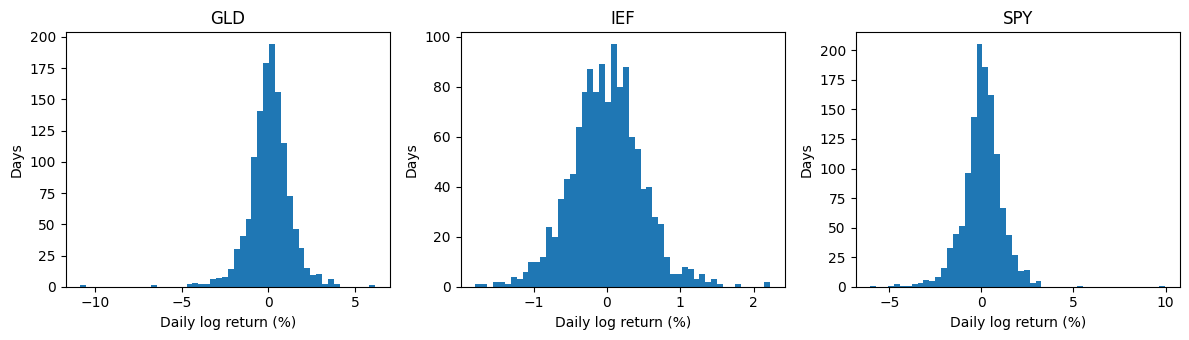

In [3]:
returns_summary = analysis.groupby('ticker').log_return.agg(n='count', median='median', std='std', skew='skew')
returns_summary['excess_kurtosis'] = analysis.groupby('ticker').log_return.apply(lambda s: s.kurt())
returns_summary[['median', 'std']] *= 100
display(returns_summary.round(4))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (ticker, group) in zip(axes, analysis.groupby('ticker')):
    ax.hist(group.log_return * 100, bins=50)
    ax.set_title(ticker)
    ax.set_xlabel('Daily log return (%)')
    ax.set_ylabel('Days')
plt.tight_layout()
plt.show()

## 3. ความผันผวนตามเวลา: RV 20 วัน (20-Day Rolling Realized Volatility)

ใช้ $RV_{20,t}=\sqrt{252\,\mathrm{mean}(r^2)}$ ภายใน 20 วันซื้อขายล่าสุด รวม warm-up ก่อนช่วงศึกษา ตารางและกราฟแสดงค่า annualized เป็น % สูตรนี้ไม่หักค่าเฉลี่ย จึงต่างจาก sample standard deviation ในหัวข้อถัดไป ค่าสูงสุดบอกช่วงรุนแรง ส่วน median ช่วยบอกระดับที่พบบ่อยกว่า

,median,p90,maximum
ticker,,,
GLD,14.70,27.46,58.26
IEF,6.74,10.58,14.35
SPY,13.63,25.47,52.43


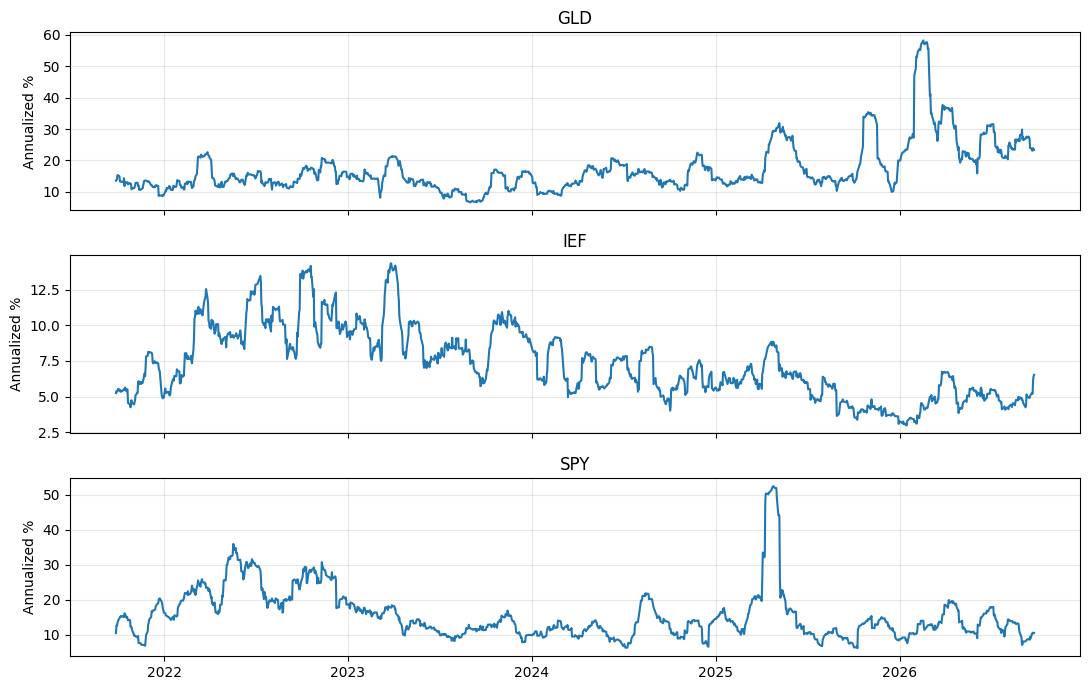

In [4]:
df = add_historical_rv(df, windows=(20,))
analysis = df.loc[~df.is_warmup_buffer].copy()
if not np.isfinite(analysis.rv_20d.to_numpy(dtype=float)).all():
    raise ValueError('RV20 ไม่พร้อมในช่วงศึกษา; ตรวจ notebook 00 ก่อน')
rv_summary = analysis.groupby('ticker').rv_20d.agg(median='median', p90=lambda s: s.quantile(.9), maximum='max') * 100
display(rv_summary.round(2))
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, (ticker, group) in zip(axes, analysis.groupby('ticker')):
    ax.plot(group.date, group.rv_20d * 100)
    ax.set_title(ticker)
    ax.set_ylabel('Annualized %')
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 4. ความผันผวนรายปี (Annual Volatility)

เปรียบเทียบ sample standard deviation ของ daily log return ในแต่ละปี คูณ $\sqrt{252}$ และแสดงเป็น % เป็นการปรับสเกลเพื่อเปรียบเทียบ ไม่ใช่ผลตอบแทนสะสมหรือการพยากรณ์

`*` หมายถึงปีที่ช่วงศึกษาไม่ครอบคลุมวันซื้อขายทั้งปี จึงไม่ควรตีความแทนทั้งปี

จำนวนวันต่อสินทรัพย์: 2021*: 68, 2022: 251, 2023: 250, 2024: 252, 2025: 250, 2026*: 184


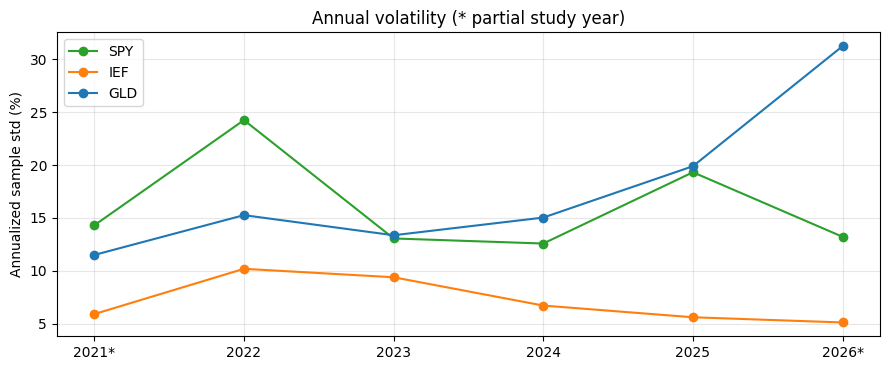

In [5]:
annual = analysis.copy()
annual['year'] = annual.date.dt.year
years = sorted(annual.year.unique())
full_sessions = calendar.schedule(start_date=f'{start_date.year}-01-01', end_date=f'{end_date.year}-12-31').index
study_sessions = pd.DatetimeIndex(expected_sessions)
study_sessions = study_sessions[(study_sessions >= start_date) & (study_sessions <= end_date)]
partial_years = {year for year in years if (study_sessions.year == year).sum() < (full_sessions.year == year).sum()}
labels = [f'{year}{"*" if year in partial_years else ""}' for year in years]
annual_std = annual.groupby(['year', 'ticker']).log_return.std().unstack('ticker') * np.sqrt(252) * 100
print('จำนวนวันต่อสินทรัพย์:', ', '.join(f'{label}: {(study_sessions.year == year).sum()}' for year, label in zip(years, labels)))
colors = {'SPY': '#2ca02c', 'IEF': '#ff7f0e', 'GLD': '#1f77b4'}
fig, ax = plt.subplots(figsize=(9, 3.8))
for ticker in config['source']['tickers']:
    ax.plot(years, annual_std[ticker], marker='o', label=ticker, color=colors[ticker])
ax.set_xticks(years, labels)
ax.set_ylabel('Annualized sample std (%)')
ax.set_title('Annual volatility (* partial study year)')
ax.grid(alpha=.3)
ax.legend()
plt.tight_layout()
plt.show()

## 5. ความสัมพันธ์ระหว่างสินทรัพย์ (Cross-Asset Correlation)

Pearson correlation ของ daily log return บอกว่าผลตอบแทนเคลื่อนไปด้วยกันมากเพียงใด ตารางใช้ข้อมูลเต็ม ส่วนกราฟ rolling 20 วันและ heatmap รายปีช่วยดูการเปลี่ยนตามเวลา ใช้วันที่ตรงกันของทั้งสามสินทรัพย์

Rolling รวม warm-up และหน้าต่างติดกันมีข้อมูลซ้อนทับกัน ค่าแต่ละช่วงจึงไม่เป็นอิสระ Correlation ไม่ได้แสดงเหตุและผล และค่าย้อนหลังไม่รับประกันอนาคต `*` ใน heatmap หมายถึงปีที่ไม่เต็มตามช่วงศึกษา

,Full-period correlation
SPY-IEF,0.097
SPY-GLD,0.152
IEF-GLD,0.300


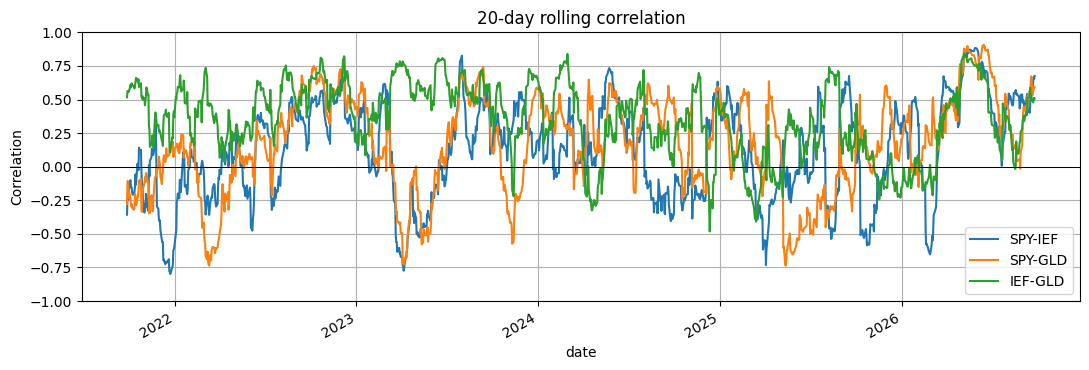

In [6]:
from src.eda.quality import annual_correlations
wide = df.pivot(index='date', columns='ticker', values='log_return').sort_index()
analysis_wide = wide.loc[start_date:end_date]
if wide.iloc[1:].isna().any().any() or analysis_wide.isna().any().any():
    raise ValueError('Correlation ต้องใช้ผลตอบแทนที่ครบและตรงวันกัน')
pairs = [('SPY', 'IEF'), ('SPY', 'GLD'), ('IEF', 'GLD')]
display(pd.DataFrame({'Full-period correlation': {f'{a}-{b}': analysis_wide[a].corr(analysis_wide[b]) for a, b in pairs}}).round(3))
rolling_corr = pd.DataFrame({f'{a}-{b}': wide[a].rolling(20, min_periods=20).corr(wide[b]) for a, b in pairs}).loc[start_date:end_date]
rolling_corr.plot(figsize=(11, 3.8), title='20-day rolling correlation', grid=True)
plt.axhline(0, color='black', linewidth=.7)
plt.ylim(-1, 1)
plt.ylabel('Correlation')
plt.tight_layout()
plt.show()

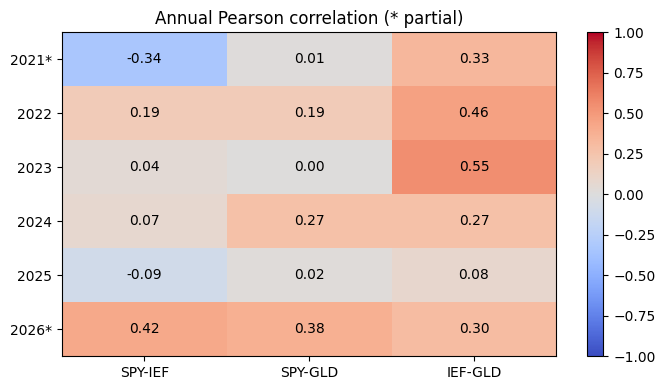

In [7]:
annual_corr = annual_correlations(annual, config['source']['tickers'], pairs)
annual_corr['period'] = np.where(annual_corr.year.isin(partial_years), 'partial study year', 'full study year')
# ใช้ heatmap แทนการแสดงตารางซ้ำ
corr_cols = [f'{a}-{b}' for a,b in pairs]
fig, ax = plt.subplots(figsize=(7,4))
values = annual_corr[corr_cols].to_numpy(dtype=float)
cmap = plt.get_cmap('coolwarm').copy(); cmap.set_bad('lightgrey')
im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(corr_cols)), corr_cols); ax.set_yticks(range(len(years)), labels)
for i in range(len(years)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f'{values[i,j]:.2f}' if np.isfinite(values[i,j]) else 'NA', ha='center', va='center')
ax.set_title('Annual Pearson correlation (* partial)'); fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

## 6. ความไวของ distribution ต่อวันสุดขั้ว (Sensitivity to Extreme Return Days)

เปรียบเทียบข้อมูลเต็มกับการเว้นวันที่มี **ค่าสัมบูรณ์ของ simple return สูงสุด** 1 และ 5 วันของแต่ละสินทรัพย์ แล้วคำนวณสถิติจาก log return ใหม่ กราฟซ้ายตั้ง std ของข้อมูลเต็มเป็น 100; กราฟขวาแสดง excess kurtosis จริง

นี่คือการดูอิทธิพลของเหตุการณ์ ไม่ใช่คำแนะนำให้ตัดข้อมูล ข้อมูลเต็มยังเป็นผลหลัก และไม่มีการเขียนทับข้อมูลต้นทาง

In [8]:
from src.eda.quality import distribution_sensitivity
events = analysis.assign(magnitude=analysis.simple_return.abs()).sort_values(
    ['ticker', 'magnitude', 'date'], ascending=[True, False, True]
).groupby('ticker', sort=True).head(5).copy()
events['rank'] = events.groupby('ticker').cumcount() + 1
dist_sensitivity = distribution_sensitivity(analysis, events)

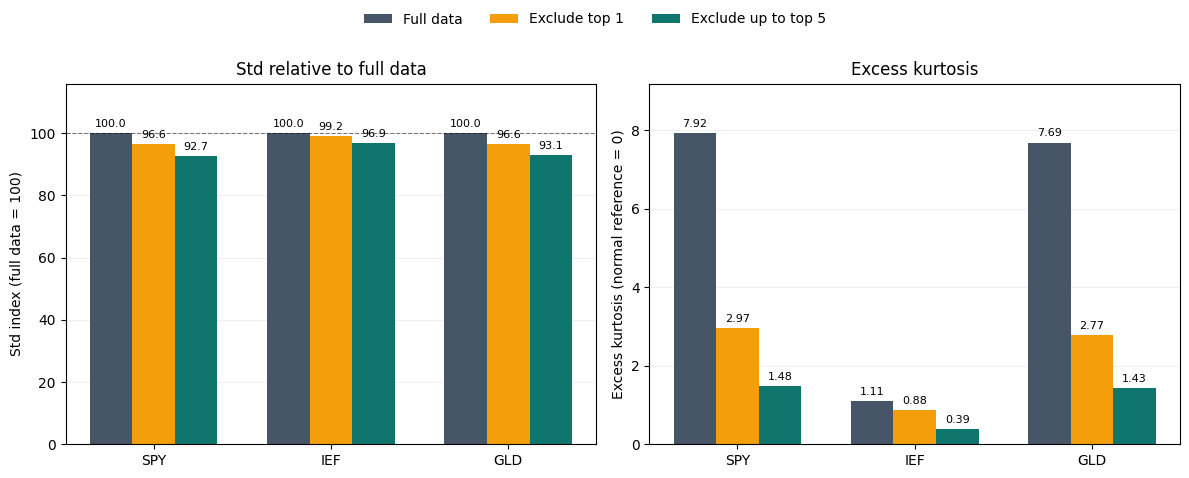

In [9]:
# กราฟ sensitivity ใช้ค่าที่คำนวณไว้ในตาราง ไม่แก้ข้อมูลต้นทาง
sensitivity_tickers = ['SPY', 'IEF', 'GLD']
sensitivity_cases = ['top-0', 'top-1', 'top-5']
sensitivity_labels = ['Full data', 'Exclude top 1', 'Exclude up to top 5']
sensitivity_colors = ['#475569', '#f59e0b', '#0f766e']
std_plot = dist_sensitivity.pivot(index='ticker', columns='case', values='std_log_pct').reindex(
    index=sensitivity_tickers, columns=sensitivity_cases
)
std_index = std_plot.div(std_plot['top-0'].replace(0, np.nan), axis=0) * 100
kurtosis_plot = dist_sensitivity.pivot(index='ticker', columns='case', values='kurtosis').reindex(
    index=sensitivity_tickers, columns=sensitivity_cases
)
x = np.arange(len(sensitivity_tickers))
width = 0.24
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, table, title, ylabel, decimals in [
    (axes[0], std_index, 'Std relative to full data', 'Std index (full data = 100)', 1),
    (axes[1], kurtosis_plot, 'Excess kurtosis', 'Excess kurtosis (normal reference = 0)', 2),
]:
    for j, case in enumerate(sensitivity_cases):
        bars = ax.bar(x + (j-1)*width, table[case], width=width,
                      label=sensitivity_labels[j], color=sensitivity_colors[j])
        ax.bar_label(bars, labels=[f'{value:.{decimals}f}' if np.isfinite(value) else 'NA'
                                  for value in table[case]], padding=3, fontsize=8)
    ax.set_xticks(x, sensitivity_tickers)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.axhline(0, color='black', linewidth=.7)
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
    ax.margins(y=.16)
axes[0].axhline(100, color='black', linestyle='--', linewidth=.8, alpha=.5)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper center', ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0, 1, .91])
plt.show()

## 7. ความต่อเนื่องของพฤติกรรม: ACF (Autocorrelation Function)

ACF เปรียบเทียบค่าปัจจุบันกับค่าก่อนหน้า `lag k` วันซื้อขาย ตารางแสดง lag 1, 5, 10 และ 20 ของ return, absolute return และ squared return จาก daily return โดยตรง จึงไม่ปนผลจากหน้าต่าง RV ที่ซ้อนทับกัน ใช้ค่าเฉลี่ยทั้งชุดและตัวหารผลรวมกำลังสองทั้งชุดในทุก lag

Return ช่วยดูความต่อเนื่องของทิศทาง ส่วน absolute/squared return ช่วยดูความต่อเนื่องของขนาดการเคลื่อนไหว `n` คือจำนวนวันทั้งหมด; lag k มีคู่ข้อมูล n−k คู่ ค่าที่พบเป็นเชิงพรรณนา ยังไม่ยืนยันนัยสำคัญหรือความสามารถพยากรณ์ และ absolute/squared return ไวต่อวันสุดขั้ว

กราฟเทียบ return กับ absolute return ที่ lag 1–20 โดยใช้สเกลแกน Y เดียวกันทุกสินทรัพย์ เส้นศูนย์หมายถึงไม่มีความสัมพันธ์เชิงเส้นที่ lag นั้น ค่าบวกของ absolute return สอดคล้องกับการกระจุกตัวของขนาดการเคลื่อนไหว แต่กราฟนี้ไม่ได้ทดสอบนัยสำคัญทางสถิติ ส่วน squared return เก็บไว้ในตารางเพื่ออ่านประกอบ

In [10]:
# เตรียม ACF โดยตรวจวันและ return ก่อนคำนวณ
from src.eda.quality import sample_acf
expected_acf = pd.DatetimeIndex(expected_sessions).tz_localize(None).normalize()
expected_acf = expected_acf[(expected_acf >= start_date) & (expected_acf <= end_date)]
acf_input = analysis.loc[analysis.date.between(start_date, end_date)].copy()
if acf_input.duplicated(['date', 'ticker']).any():
    raise ValueError('ACF: พบ date/ticker ซ้ำ')
acf_values = {}
acf_rows = []
for ticker in config['source']['tickers']:
    group = acf_input.loc[acf_input.ticker.eq(ticker)].sort_values('date')
    dates = pd.DatetimeIndex(group.date)
    if not dates.equals(expected_acf):
        raise ValueError(f'ACF: {ticker} มีวันซื้อขายขาดหรือเกินช่วงที่กำหนด')
    r = group.log_return.to_numpy(dtype=float)
    if not np.isfinite(r).all():
        raise ValueError(f'ACF: {ticker} มี log return ที่ไม่ใช่ finite')
    with np.errstate(over='ignore', invalid='ignore'):
        series = {'Return': r, 'Absolute return': np.abs(r), 'Squared return': np.square(r)}
    for kind, values in series.items():
        if not np.isfinite(values).all():
            raise ValueError(f'ACF: {ticker} {kind} ไม่เป็น finite หลังแปลงข้อมูล')
        result = sample_acf(values, 20)
        acf_values[(ticker, kind)] = result
        acf_rows.append({'สินทรัพย์': ticker, 'ชนิดข้อมูล': kind, 'n': len(values),
                         **{f'lag {k}': result[k] for k in (1, 5, 10, 20)}})
acf_summary = pd.DataFrame(acf_rows)


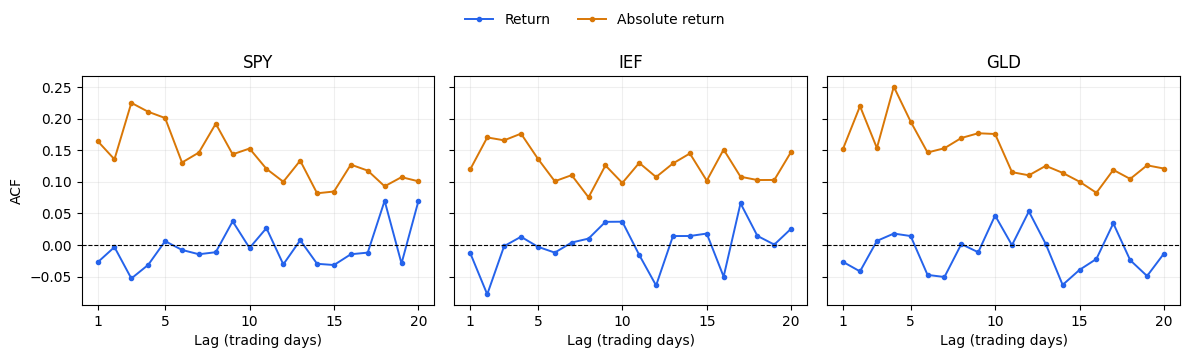

In [11]:
# ใช้ ACF ที่คำนวณไว้ แสดงเฉพาะทิศทางและขนาดเพื่อให้กราฟกระชับ
acf_tickers = config['source']['tickers']
fig, axes = plt.subplots(1, len(acf_tickers), figsize=(12, 3.6), sharex=True, sharey=True, squeeze=False)
for ax, ticker in zip(axes[0], acf_tickers):
    for kind, color in [('Return', '#2563eb'), ('Absolute return', '#d97706')]:
        values = acf_values[(ticker, kind)][1:21]
        ax.plot(np.arange(1, len(values) + 1), values, marker='.', linewidth=1.4,
                color=color, label=kind)
    ax.axhline(0, color='black', linewidth=.8, linestyle='--')
    ax.set_title(ticker)
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.set_xlabel('Lag (trading days)')
    ax.grid(alpha=.2)
axes[0, 0].set_ylabel('ACF')
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper center', ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, .90])
plt.show()

In [12]:
display(acf_summary.round(4))


,สินทรัพย์,ชนิดข้อมูล,n,lag 1,lag 5,lag 10,lag 20
0,SPY,Return,1255,-0.0275,0.0061,-0.0047,0.0696
1,SPY,Absolute return,1255,0.1648,0.2011,0.1528,0.1009
2,SPY,Squared return,1255,0.1991,0.0974,0.0661,0.0274
3,IEF,Return,1255,-0.0132,-0.0028,0.0369,0.0259
4,IEF,Absolute return,1255,0.1201,0.1366,0.0983,0.1477
5,IEF,Squared return,1255,0.1008,0.1137,0.0449,0.0982
6,GLD,Return,1255,-0.0268,0.0142,0.0467,-0.0135
7,GLD,Absolute return,1255,0.1527,0.1954,0.1758,0.1211
8,GLD,Squared return,1255,0.1551,0.1036,0.0906,0.0482


## 8. สรุปผล EDA (Key Findings)

จากการศึกษาผลตอบแทนรายวันและความผันผวนของ `SPY`, `IEF` และ `GLD` ตั้งแต่ 27 กันยายน 2021 ถึง 25 กันยายน 2026 โดยใช้ข้อมูลเต็ม 1,255 วันซื้อขายต่อสินทรัพย์ ผลสำรวจมีข้อสังเกตดังนี้

1. **การกระจายของผลตอบแทน (Return Distribution):** `IEF` มีส่วนเบี่ยงเบนมาตรฐานของ log return รายวันต่ำที่สุดที่ 0.49% เทียบกับ 1.08% ของ `SPY` และ 1.19% ของ `GLD` ส่วน excess kurtosis ของ `SPY` และ `GLD` อยู่ที่ 7.92 และ 7.69 ตามลำดับ สูงกว่า `IEF` ที่ 1.11 ผลการทดลองในข้อ 4 ช่วยให้เห็นว่าวันที่เคลื่อนไหวแรงมีอิทธิพลต่อค่าเหล่านี้มากเพียงใด สำหรับ `GLD` ค่า skewness อยู่ที่ −0.80 สะท้อนว่าการกระจายของผลตอบแทนเบ้ไปทางลบ

2. **ความผันผวนในแต่ละช่วง (Volatility over Time):** ความผันผวนย้อนหลัง 20 วัน (`RV20`) ของ `GLD` และ `SPY` มีค่ากลางใกล้กันที่ 14.70% และ 13.63% ในสเกลรายปี แต่ค่าสูงสุดขึ้นไปถึง 58.26% และ 52.43% ตามลำดับ เมื่อแยกดูรายปี ลำดับความผันผวนก็เปลี่ยนได้ เช่น ในปี 2022 `SPY` ผันผวนกว่า `GLD` แม้เมื่อรวมทั้งช่วง `GLD` จะมีส่วนเบี่ยงเบนมาตรฐานรายวันสูงกว่า `SPY` การเปรียบเทียบรายปีควรคำนึงด้วยว่าปี 2021 และ 2026 ครอบคลุมเพียงบางส่วนของปี

3. **ความสัมพันธ์ระหว่างสินทรัพย์ (Cross-Asset Correlation):** Pearson correlation ทั้งช่วงอยู่ที่ 0.097 สำหรับ `SPY–IEF`, 0.152 สำหรับ `SPY–GLD` และ 0.300 สำหรับ `IEF–GLD` เมื่อเลื่อนหน้าต่างคำนวณทีละวัน กราฟย้อนหลัง 20 วันแสดงทั้งช่วงที่ค่าเป็นบวกและช่วงที่ติดลบ ตารางทั้งช่วงจึงให้ภาพรวม ส่วนกราฟย้อนหลังช่วยให้เห็นว่าความสัมพันธ์ในช่วงใดต่างจากภาพรวมนั้น

4. **ผลของวันสุดขั้วต่อการกระจาย (Impact of Extreme Return Days):** เมื่อทดลองเว้น 5 วันที่มีค่าสัมบูรณ์ของ simple return สูงที่สุดของแต่ละสินทรัพย์ ค่า excess kurtosis ของ `SPY` ลดจาก 7.92 เหลือ 1.48 และของ `GLD` ลดจาก 7.69 เหลือ 1.43 ขณะที่ส่วนเบี่ยงเบนมาตรฐานลดลงประมาณ 7% ทั้งสองตัว วันไม่กี่วันจึงมีผลต่อข้อสังเกตเรื่องหางการกระจายมากกว่าที่เห็นจากการเปลี่ยนแปลงของส่วนเบี่ยงเบนมาตรฐาน รายการที่ตรวจเทียบในโน้ตบุ๊กตรวจคุณภาพและเตรียมข้อมูลสอดคล้องกับ raw snapshot จึงใช้ข้อมูลเต็มเป็นฐานสำหรับสร้างฟีเจอร์ชุดแรก

5. **ความต่อเนื่องของขนาดการเคลื่อนไหว (Persistence of Return Magnitude):** ACF ของ absolute return มีค่าบวกและเด่นกว่า ACF ของ return ในหลาย lag ของทั้งสามสินทรัพย์ เช่น ที่ lag 1 ของ `SPY` ค่า ACF ของ absolute return อยู่ที่ 0.1648 เทียบกับ −0.0275 ของ return รูปแบบนี้สอดคล้องกับ volatility clustering คือช่วงที่ราคาเคลื่อนไหวแรงมักเกิดใกล้กัน แม้ทิศทางจะสลับขึ้นลงได้ ข้อสังเกตนี้ให้เหตุผลที่จะเริ่มจากฟีเจอร์ความผันผวนย้อนหลัง ส่วนประโยชน์ต่อการพยากรณ์ต้องวัดในขั้นประเมินโมเดล